# Prepare and Synthesize: the 200k Balanced Training Set (cmu + synthetic)

## 1. Introduction

This is the first of three notebooks for the second logistic regression model. It uses the same five-step workflow as the 70k model, but the training data is different:

| Model | Training data |
|---|---|
| `05_modeling_logreg` (70k) | 28,078 real diabetes rows + 28,077 real no-diabetes rows |
| `07_modeling_cmu` (200k) | **100,000 diabetes rows (real + synthetic) + 100,000 real no-diabetes rows** |

We start from the **unbalanced** table (`diabetes_final_clean_merged_unbalanced`: 229,474 rows, 194,377 without diabetes and 35,097 with diabetes). The balanced table of the 70k model throws away most of the no-diabetes rows. Here we keep many more of them, and only the *missing* diabetes rows are synthetic.

### The one rule that shapes this whole notebook
> **The test set must stay real and untouched.**

The 70k model was tested on `diabetes_model_test` (14,039 real people). To compare the 70k and 200k models fairly, the 200k model is tested on **the same 14,039 people**. That has two consequences:

1. **The test rows are removed from the pool before anything else.** If a test person were also in the 200k training set, the score would be inflated (data leakage).
2. **Synthetic rows are made from training rows only.** A synthetic row is an interpolation between real rows. If it were made from a test person, the model would be trained on a blurry copy of that person.

So the "200k dataset" is a **200k training set**. The test set is separate, real, and the same as before.

### What changes compared with the plan "remove 94,377 rows, add 64,903 synthetic rows"
The idea is right, but the numbers change once the 14,039 test people are set aside first:

| | Plan without reserving the test set | This notebook |
|---|---|---|
| Real diabetes rows available | 35,097 | 35,097 - 7,019 = **28,078** |
| Real no-diabetes rows available | 194,377 | 194,377 - 7,020 = **187,357** |
| No-diabetes rows removed | 94,377 | **87,357** (and 7,020 are in the test set) |
| Synthetic diabetes rows needed | 64,903 | **71,922** |

**Output:** one training table with 200,000 rows and a flag `is_synthetic`, saved to the database and as a CSV file.

In this notebook we:

1. Load the unbalanced table and the saved test set.
2. Remove the test rows from the pool.
3. Randomly keep 100,000 no-diabetes rows.
4. Create 71,922 synthetic diabetes rows from the real diabetes rows.
5. Check how realistic the synthetic rows are.
6. Assemble the 200k training set and run the leakage checks.
7. Save it.

## 2. Import Libraries and Connect

`synth_utils.py` (in this folder) contains the function that creates the synthetic rows. It needs only numpy, pandas and scikit-learn.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# scikit-learn: used only for the "can a model tell real from synthetic?" check
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

# SQLAlchemy: creates the connection between Python and the MariaDB database
from sqlalchemy import create_engine, text

# Our own helper file in this folder
from synth_utils import generate_synthetic, FEATURES, BINARY, NUMERIC, TARGET

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

engine = create_engine("mysql+pymysql://root:@localhost:3306/diabetes_final_db")

# Tables and settings
SOURCE_TABLE = "diabetes_final_clean_merged_unbalanced"   # CHANGE if your table has another name
TEST_TABLE = "diabetes_model_test"                        # the same real test set as the 70k model
OUT_TABLE = "diabetes_cmu_synth_train"                    # the table we create
OUT_CSV = Path("../../data/07_cmu+synthetic/diabetes_cmu_synthetic_train.csv")
N_PER_CLASS = 100_000        # rows per class in the training set
RANDOM_STATE = 42            # fixed seed, so everything can be repeated exactly

with engine.connect() as conn:
    conn.execute(text("SELECT 1"))

print("Libraries imported and database connection successful.")

Libraries imported and database connection successful.


## 3. Load the Unbalanced Table and the Test Set

We confirm that the table is what we expect (229,474 rows: 194,377 without and 35,097 with diabetes) and load the saved test set. The test set is **not used to train or tune anything**. We only need to know which people are in it, so that we can keep them out of the training data.

In [2]:
df = pd.read_sql(f"SELECT * FROM {SOURCE_TABLE}", con=engine)
test_df = pd.read_sql(f"SELECT * FROM {TEST_TABLE}", con=engine)

ready = pd.DataFrame({
    "Check": ["Rows", "No diabetes (0)", "Diabetes (1)", "Missing values", "Duplicate rows",
              "All columns are integers", "Test set rows"],
    "Result": [f"{len(df):,}", f"{(df[TARGET] == 0).sum():,}", f"{(df[TARGET] == 1).sum():,}",
               int(df.isnull().sum().sum()), int(df.duplicated().sum()),
               all(pd.api.types.is_integer_dtype(t) for t in df.dtypes), f"{len(test_df):,}"],
})
display(ready.style.hide(axis="index"))

print(f"'{SOURCE_TABLE}' and '{TEST_TABLE}' loaded successfully.")

Check,Result
Rows,"229,474"
No diabetes (0),"194,377"
Diabetes (1),"35,097"
Missing values,0
Duplicate rows,0
All columns are integers,True
Test set rows,"14,039"


'diabetes_final_clean_merged_unbalanced' and 'diabetes_model_test' loaded successfully.


## 4. Set the Test People Aside

We find each test row in the unbalanced table and remove it. What is left is the **pool**: the only real rows the 200k training set may use.

The check `Every test row was found` matters. If it fails, the test set contains rows that are not in the unbalanced table, and the numbers in this notebook have to be re-derived.

In [3]:
# Mark the rows of df that are also in the test set (merge on all 22 columns)
marked = df.merge(test_df.drop_duplicates(), on=list(df.columns), how="left", indicator=True)
in_test = (marked["_merge"] == "both").to_numpy()
pool = marked.loc[~in_test].drop(columns="_merge").reset_index(drop=True)

pos_pool = pool[pool[TARGET] == 1]     # real diabetes rows we may train on
neg_pool = pool[pool[TARGET] == 0]     # real no-diabetes rows we may train on

pool_table = pd.DataFrame({
    "Item": ["Test rows found in the unbalanced table", "Every test row was found",
             "Pool: rows left for training", "Pool: no diabetes (0)", "Pool: diabetes (1)"],
    "Value": [f"{int(in_test.sum()):,}", int(in_test.sum()) == len(test_df.drop_duplicates()),
              f"{len(pool):,}", f"{len(neg_pool):,}", f"{len(pos_pool):,}"],
})
display(pool_table.style.hide(axis="index"))

Item,Value
Test rows found in the unbalanced table,"14,039"
Every test row was found,True
Pool: rows left for training,"215,435"
Pool: no diabetes (0),"187,357"
Pool: diabetes (1),"28,078"


**Interpretation:** All 14,039 test rows were found in the unbalanced table, so the test set is a clean subset of this data and could be removed exactly. The pool that is left has 215,435 rows: 187,357 without diabetes and 28,078 with diabetes. That is 7,020 and 7,019 rows fewer than in the unbalanced table, which matches the size of the test set. From here on, only the pool may be used for training.

## 5. Keep 100,000 No-Diabetes Rows

We randomly keep 100,000 of the no-diabetes rows in the pool and leave the rest unused. Random sampling with a fixed seed keeps the same mix of people as the pool (no age group or income group is favoured), and anyone can repeat it.

In [4]:
neg_real = neg_pool.sample(n=N_PER_CLASS, random_state=RANDOM_STATE)
pos_real = pos_pool.copy()                                  # keep every real diabetes row

n_new = N_PER_CLASS - len(pos_real)                         # synthetic diabetes rows needed

plan = pd.DataFrame({
    "Item": ["No-diabetes rows kept", "No-diabetes rows left unused", "Real diabetes rows",
             "Synthetic diabetes rows needed", "Synthetic share of the diabetes class"],
    "Value": [f"{len(neg_real):,}", f"{len(neg_pool) - len(neg_real):,}", f"{len(pos_real):,}",
              f"{n_new:,}", f"{n_new / N_PER_CLASS:.1%}"],
})
display(plan.style.hide(axis="index"))

Item,Value
No-diabetes rows kept,"100,000"
No-diabetes rows left unused,"87,357"
Real diabetes rows,"28,078"
Synthetic diabetes rows needed,"71,922"
Synthetic share of the diabetes class,71.9%


**Interpretation:** We keep 100,000 of the 187,357 no-diabetes rows and leave 87,357 unused. Every one of the 28,078 real diabetes rows is kept, so **71,922 synthetic rows** are needed, which is 71.9% of the diabetes class. This is more than the 64,903 in our first plan, because the 7,019 diabetes people in the test set cannot be used for training. The unused rows are not lost information: they stay in the unbalanced table.

### A caution about the synthetic share
Almost three quarters of the diabetes class will be synthetic. A synthetic row is an interpolation between real people, so it adds **no new information**. It only makes the existing 28,078 diabetes people count more in training. We should therefore not expect a big jump in accuracy compared with the 70k model. The comparison in `08_model_comparison` will show whether the extra rows help at all.

## 6. Create the Synthetic Diabetes Rows

**Method (SMOTE idea, adapted to survey data).** SMOTE creates a new person *between* two similar real people. For each synthetic person:

1. Pick a real diabetes person at random (the **base**).
2. Pick one of the base's 5 most similar real diabetes people (the **neighbour**). Similarity uses the numeric answers (standardized) and the Yes/No answers.
3. Draw a random fraction `gap` between 0 and 1.
4. **Numeric answers** (BMI, GenHlth, MentHlth, PhysHlth, Age, Education, Income): `base + gap x (neighbour - base)`, rounded to a whole number and kept inside the real range.
5. **Yes/No answers:** copied from the base with probability `1 - gap`, otherwise from the neighbour. (Averaging 0 and 1 would give meaningless values such as 0.4 for "Smoker".)

Every synthetic row that is identical to a real training row, to a test row, or to another synthetic row is thrown away and replaced, so each one is genuinely new.

All the work happens on **diabetes rows only**, and only on rows that are not in the test set.

In [5]:
synthetic = generate_synthetic(pos_real, n_new, k=5, seed=RANDOM_STATE, avoid=test_df)

print(f"Created {len(synthetic):,} synthetic diabetes rows.")
display(synthetic.head())

Created 71,922 synthetic diabetes rows.


,HighBP,HighChol,CholCheck,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,DiffWalk,Sex,BMI,GenHlth,MentHlth,PhysHlth,Age,Education,Income
0,0,1,1,1,0,0,1,1,1,0,1,0,0,1,26,4,0,0,10,4,7
1,1,0,1,0,0,0,1,1,1,0,1,0,0,0,28,3,0,0,11,4,2
2,0,1,1,1,0,0,1,0,1,0,1,0,0,0,41,4,0,0,10,4,8
3,1,1,1,0,0,0,0,1,1,0,1,0,0,0,27,2,0,1,10,6,6
4,1,1,1,0,0,0,0,1,1,0,1,0,1,1,25,5,0,30,7,5,4


## 7. How Realistic Are the Synthetic Rows?

Synthetic data is only useful if it looks like the real data it came from. Four checks:

1. **Valid values:** same columns, whole numbers, inside the real range.
2. **Averages:** each answer's average in the real and synthetic diabetes rows.
3. **Relationships:** the correlations between answers.
4. **Can a model tell them apart?** A random forest tries to separate real from synthetic diabetes rows. An ROC AUC of 0.50 would mean it cannot. Synthetic rows made by interpolation are never perfectly indistinguishable, so we only look for a result that is not extreme.

### 7.1 Valid values

In [6]:
checks = pd.DataFrame({
    "Check": ["Same columns as the real rows", "All values are whole numbers",
              "Binary answers contain only 0 and 1", "Numeric answers stay inside the real range",
              "No missing values"],
    "Passed": [
        list(synthetic.columns) == FEATURES,
        all(pd.api.types.is_integer_dtype(t) for t in synthetic.dtypes),
        bool(synthetic[BINARY].isin([0, 1]).all().all()),
        bool(((synthetic[NUMERIC].min() >= pos_real[NUMERIC].min()) &
              (synthetic[NUMERIC].max() <= pos_real[NUMERIC].max())).all()),
        int(synthetic.isnull().sum().sum()) == 0,
    ],
})
display(checks.style.hide(axis="index"))

Check,Passed
Same columns as the real rows,True
All values are whole numbers,True
Binary answers contain only 0 and 1,True
Numeric answers stay inside the real range,True
No missing values,True


### 7.2 Averages

For a Yes/No answer the average is the share of "Yes". The column `No diabetes (real)` is there for comparison: a good synthetic row should look like the diabetes people, not like the others.

,Real diabetes,Synthetic diabetes,No diabetes (real),Difference (synthetic - real),Difference as % of real
HighBP,0.752,0.772,0.399,0.020,2.606
HighChol,0.670,0.688,0.401,0.018,2.716
CholCheck,0.993,0.995,0.952,0.003,0.256
Smoker,0.521,0.533,0.456,0.013,2.457
Stroke,0.093,0.088,0.036,-0.006,-6.278
HeartDiseaseorAttack,0.224,0.226,0.081,0.002,1.000
PhysActivity,0.627,0.603,0.752,-0.024,-3.753
Fruits,0.583,0.575,0.617,-0.008,-1.337
Veggies,0.753,0.755,0.801,0.002,0.264
HvyAlcoholConsump,0.023,0.017,0.068,-0.006,-26.539


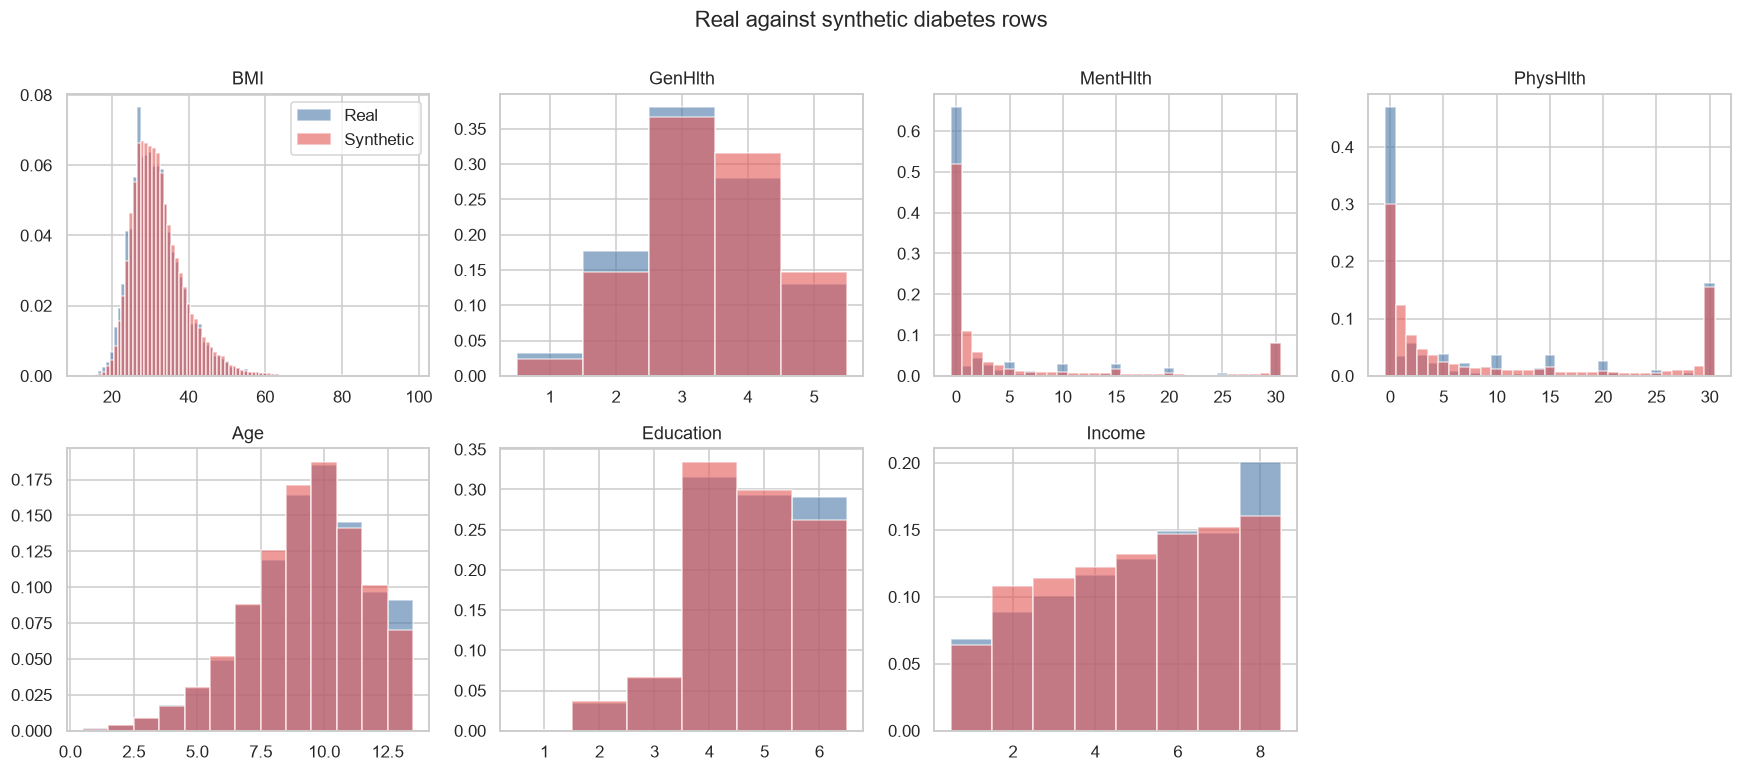

In [7]:
avg = pd.DataFrame({
    "Real diabetes": pos_real[FEATURES].mean(),
    "Synthetic diabetes": synthetic[FEATURES].mean(),
    "No diabetes (real)": neg_real[FEATURES].mean(),
})
avg["Difference (synthetic - real)"] = avg["Synthetic diabetes"] - avg["Real diabetes"]
avg["Difference as % of real"] = avg["Difference (synthetic - real)"] / avg["Real diabetes"] * 100
display(avg.round(3))

# Distribution of the numeric answers: real against synthetic
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), NUMERIC):
    bins = np.arange(pos_real[col].min(), pos_real[col].max() + 2) - 0.5
    ax.hist(pos_real[col], bins=bins, density=True, alpha=0.6, label="Real", color="#4C78A8")
    ax.hist(synthetic[col], bins=bins, density=True, alpha=0.6, label="Synthetic", color="#E45756")
    ax.set_title(col)
axes.ravel()[0].legend()
axes.ravel()[-1].axis("off")
plt.suptitle("Real against synthetic diabetes rows", y=1.00)
plt.tight_layout()
plt.show()

**Interpretation:** The synthetic rows are close to the real diabetes rows and clearly different from the no-diabetes rows. For example, HighBP is 0.752 in the real diabetes rows, 0.772 in the synthetic rows and 0.399 in the no-diabetes rows. Most Yes/No answers differ by less than 0.03. The biggest differences are `DiffWalk` (0.374 real against 0.422 synthetic, +12.7%), `MentHlth` (+17.9%), `PhysHlth` (+14.7%) and `HvyAlcoholConsump` (-26.5%, but only because the rate is tiny: 0.023 against 0.017). The histograms show where the `MentHlth` and `PhysHlth` shift comes from. In the real rows, 66% (`MentHlth`) and 47% (`PhysHlth`) of the people answered exactly 0 days, but in the synthetic rows it is only about 52% and 30%. The synthetic rows have more small values (1 to 3 days), because averaging a 0 with a non-zero answer gives an in-between number, and the real data's spikes at 10, 15 and 20 days (people round their answers) are smoothed away. The spike at 30 days is kept. `BMI` and `Age` follow the real shape closely, and `GenHlth` and `Income` shift a little towards the less healthy and lower-income answers. These shifts are small, but they are the reason we do not treat synthetic rows as equal to real rows.

### 7.3 Relationships between answers

Largest difference between a real and a synthetic correlation: 0.023
Average difference: 0.0080


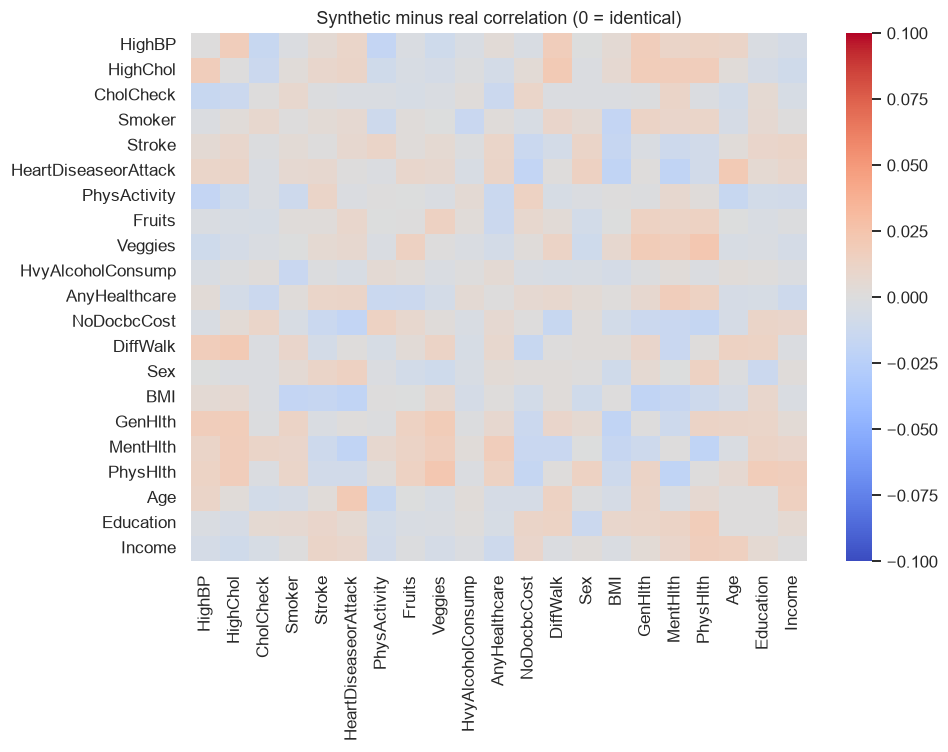

In [8]:
corr_real = pos_real[FEATURES].corr()
corr_syn = synthetic[FEATURES].corr()
diff = (corr_syn - corr_real).abs()

print(f"Largest difference between a real and a synthetic correlation: {diff.to_numpy().max():.3f}")
print(f"Average difference: {diff.to_numpy()[np.triu_indices(len(FEATURES), 1)].mean():.4f}")

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr_syn - corr_real, cmap="coolwarm", center=0, vmin=-0.1, vmax=0.1, ax=ax)
ax.set_title("Synthetic minus real correlation (0 = identical)")
plt.tight_layout()
plt.show()

**Interpretation:** The relationships between answers are preserved. The largest difference between a real and a synthetic correlation is only 0.023, and the average difference is 0.008. Every square of the heatmap is pale, within about 0.025 of zero, so the pairs of answers that go together in the real data still go together in the synthetic data. A few pairs, such as `HighBP` with `HighChol` and the health-status questions (`GenHlth`, `MentHlth`, `PhysHlth`) with other answers, are very slightly stronger in the synthetic rows (light red), but nothing is large enough to matter.

### 7.4 Can a model tell real from synthetic?

We take an equal number of real and synthetic diabetes rows and ask a random forest to separate them, with 3-fold cross-validation.

In [9]:
n = min(len(pos_real), len(synthetic))
rs = pd.concat([pos_real[FEATURES].sample(n, random_state=RANDOM_STATE),
                synthetic.sample(n, random_state=RANDOM_STATE)])
is_syn = np.r_[np.zeros(n), np.ones(n)]

forest = RandomForestClassifier(n_estimators=100, max_depth=10, n_jobs=-1, random_state=RANDOM_STATE)
auc = cross_val_score(forest, rs, is_syn, scoring="roc_auc",
                      cv=StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE))
print(f"ROC AUC for telling real from synthetic: {auc.mean():.3f} (0.50 = cannot tell, 1.00 = always can)")

ROC AUC for telling real from synthetic: 0.650 (0.50 = cannot tell, 1.00 = always can)


**Interpretation:** A random forest can tell real from synthetic diabetes rows with a ROC AUC of **0.650**. That is clearly better than guessing (0.50), so the synthetic rows are **not perfectly realistic**, which agrees with the shifts we saw in section 7.2. But it is far from 1.00, so the rows are not obviously fake either: a tree model that is trying hard finds them hard to separate. This is typical for interpolated data. The real test of usefulness is not this check but the score on the real test set in `03_evaluate`.

## 8. Assemble the 200k Training Set

We stack the three parts, add the column `is_synthetic` (0 = real, 1 = synthetic) and shuffle the rows with a fixed seed. The column `is_synthetic` is **not a feature**. It is kept so that later notebooks can tell real rows from synthetic ones (for example, to cross-validate on real rows only).

In [10]:
pos_part = pos_real.assign(is_synthetic=0)
neg_part = neg_real.assign(is_synthetic=0)
syn_part = synthetic.assign(**{TARGET: 1, "is_synthetic": 1})

train_200k = (pd.concat([pos_part, neg_part, syn_part], ignore_index=True)
                .sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True))
train_200k = train_200k[[TARGET] + FEATURES + ["is_synthetic"]]     # target first, like the other tables

summary = pd.DataFrame({
    "Part": ["No diabetes, real", "Diabetes, real", "Diabetes, synthetic", "Total"],
    "Rows": [len(neg_part), len(pos_part), len(syn_part), len(train_200k)],
})
summary["% of training set"] = (summary["Rows"] / len(train_200k) * 100).round(1)
display(summary.style.hide(axis="index"))

print("Class balance (% diabetes):", f"{train_200k[TARGET].mean() * 100:.2f}%")
print("Synthetic rows in the whole training set:", f"{train_200k['is_synthetic'].mean() * 100:.1f}%")

Part,Rows,% of training set
"No diabetes, real",100000,50.000000
"Diabetes, real",28078,14.000000
"Diabetes, synthetic",71922,36.000000
Total,200000,100.000000


Class balance (% diabetes): 50.00%
Synthetic rows in the whole training set: 36.0%


## 9. Leakage Checks

| Source of leakage | How we checked |
|---|---|
| **Test person in the training set** | No real training row is identical to a test row |
| **Synthetic copy of a test person** | No synthetic row is identical to a test row |
| **Synthetic copy of a real row** | No synthetic row is identical to a real training row (rows are new, not duplicated) |
| **Duplicates inside the training set** | No row appears twice |
| **Synthetic rows built from test people** | Synthetic rows were created from `pos_real`, which was taken from the pool *after* the test rows were removed |
| **Target as a feature** | The target is not among the features, and neither is `is_synthetic` |

The test set itself is unchanged: it is read from the database and never modified.

In [11]:
feat_cols = FEATURES + [TARGET]
test_key = test_df[feat_cols].drop_duplicates()
real_rows = train_200k.loc[train_200k["is_synthetic"] == 0, feat_cols]
syn_rows = train_200k.loc[train_200k["is_synthetic"] == 1, feat_cols]

real_in_test = len(real_rows.merge(test_key, how="inner"))
syn_in_test = len(syn_rows.merge(test_key, how="inner"))
syn_in_real = len(syn_rows.merge(real_rows.drop_duplicates(), how="inner"))

leakage = pd.DataFrame({
    "Check": ["No real training row is in the test set",
              "No synthetic row is identical to a test row",
              "No synthetic row is identical to a real training row",
              "No duplicate rows in the training set",
              "Target and is_synthetic are not features",
              "Test set still has its original size (14,039 rows)"],
    "Passed": [real_in_test == 0, syn_in_test == 0, syn_in_real == 0,
               int(train_200k[feat_cols].duplicated().sum()) == 0,
               TARGET not in FEATURES and "is_synthetic" not in FEATURES,
               len(test_df) == 14039],
})
display(leakage.style.hide(axis="index"))

print("Real rows also in test:", real_in_test, "| synthetic rows also in test:", syn_in_test,
      "| synthetic rows copying a real row:", syn_in_real)
print("ALL LEAKAGE CHECKS PASSED" if leakage["Passed"].all() else "SOME CHECKS FAILED: review the table above.")

Check,Passed
No real training row is in the test set,True
No synthetic row is identical to a test row,True
No synthetic row is identical to a real training row,True
No duplicate rows in the training set,True
Target and is_synthetic are not features,True
"Test set still has its original size (14,039 rows)",True


Real rows also in test: 0 | synthetic rows also in test: 0 | synthetic rows copying a real row: 0
ALL LEAKAGE CHECKS PASSED


## 10. Save the Training Set

The training set is saved as a table in `diabetes_final_db` (read by `02_train` and `03_evaluate`) and as a CSV file in `data/07_cmu+synthetic`. The test set is **not** saved again: `07_modeling_cmu` uses the existing `diabetes_model_test`.

In [12]:
# Database table
train_200k.to_sql(OUT_TABLE, con=engine, if_exists="replace", index=False, chunksize=10_000)

# CSV file
OUT_CSV.parent.mkdir(parents=True, exist_ok=True)
train_200k.to_csv(OUT_CSV, index=False)

# Verify by counting what was actually saved
with engine.connect() as conn:
    saved_rows = conn.execute(text(f"SELECT COUNT(*) FROM {OUT_TABLE}")).scalar()
csv_rows = len(pd.read_csv(OUT_CSV))

saved = pd.DataFrame({
    "Where": [f"Database table {OUT_TABLE}", str(OUT_CSV)],
    "Rows saved": [f"{saved_rows:,}", f"{csv_rows:,}"],
    "Matches the DataFrame": [saved_rows == len(train_200k), csv_rows == len(train_200k)],
})
display(saved.style.hide(axis="index"))

print("Training set saved successfully.")

Where,Rows saved,Matches the DataFrame
Database table diabetes_cmu_synth_train,"200,000",True
..\..\data\07_cmu+synthetic\diabetes_cmu_synthetic_train.csv,"200,000",True


Training set saved successfully.


## 11. Summary

**What we did in this notebook**
1. Loaded `diabetes_final_clean_merged_unbalanced` (229,474 rows) and the saved test set (14,039 rows).
2. Removed the test people from the pool, leaving 187,357 no-diabetes and 28,078 diabetes rows.
3. Randomly kept 100,000 no-diabetes rows.
4. Created 71,922 synthetic diabetes rows from the 28,078 real diabetes training rows.
5. Checked how realistic the synthetic rows are (values, averages, correlations, real-against-synthetic model).
6. Assembled the 200,000-row training set and ran the leakage checks.
7. Saved it as `diabetes_cmu_synth_train` and as a CSV.

**Key results**
- **Training set:** 200,000 rows: 100,000 without diabetes (all real) and 100,000 with diabetes (28,078 real + 71,922 synthetic).
- **Realism:** largest difference in an average 0.047 for `DiffWalk` (the largest in relative terms: -26.5% for `HvyAlcoholConsump`, +17.9% for `MentHlth`); largest difference in a correlation 0.023; real-against-synthetic ROC AUC 0.650.
- **Leakage checks:** all passed: no test row in the training set, no synthetic row copying a real or a test row, no duplicates.

**Decisions carried forward**
- The test set is the same real 14,039 people as for the 70k model, so the two models can be compared directly.
- Synthetic rows exist only in the training set. Cross-validation in `02_train` is done on real rows only, with synthetic rows created inside each fold, because synthetic rows made from a validation person would otherwise leak.

**Limitations**
- About 72% of the diabetes class is synthetic. It carries no new information beyond the 28,078 real people.
- The synthetic rows are slightly more extreme than the real ones on some answers (see section 7.2).

**Next step:** `02_train`.